# 11.Huckel
### Física Electrónica - UTN FRA
*Cuaderno interactivo adaptado para Google Colab.*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)


In [ ]:
#@title
from google.colab import files 
from IPython.display import Image
uploaded=files.upload()

Saving pi.png to pi.png


In [1]:
import math as m
from sympy import *
init_printing()
x=symbols('x',real=True,Negative=True)
alpha,beta=symbols('alpha,beta')

import matplotlib as mp
import matplotlib.pyplot as plt


# Ecuación polinomial ascociada al determinante secular

def Pol(A):
    return(det(A))

# Valores de energía de los orbitales moleculares (de mayor a menor), el argumento A es la matrix asociada al sistema molecular


def Energia(A):
    p=det(A) 
    S=real_roots(p,multiple=True)
    SO=sorted(S,reverse=True)
    E=[]
    for i in range(0,len(SO)):
        E_i=alpha-round(N(SO[i]),5)*beta
        E.append(E_i)
    E
    D=[]
    # Valores de energía non valores decimales
    for i in range(0,len(E)):
        D.append(E[i])
    return(D)

# Raices del polinomio asociado de menor a mayor 

def Raiz(A):
    p=det(A) 
    S=real_roots(p,multiple=True)
    SO=sorted(S)    
    return(SO)

# Gráfico de las enenrgías

def GrafE(A):
    X=Raiz(A)
    l=len(X)
    E=Energia(A)
    for i in range(0,l-1): 
        if X[i] < X[i+1]:
            plt.plot([2,3],[X[i],X[i]])
        if X[i] == X[i+1]:
            plt.plot([2,3],[X[i],X[i]])
            plt.plot([3.5,4.5],[X[i],X[i]])
        plt.plot([2,3],[X[-1],X[-1]])
        plt.plot([2,5],[0,0],ls=':',c='g')
        plt.xticks([])
        plt.yticks([])
        plt.title('Niveles de Energía de los OM')
        plt.ylabel('$Aumenta \Longrightarrow$')
    return(E)    
        
# Valores de energía de los orbitales moleculares (de menor a mayor), el argumento A es la matrix asociada al sistema molecular

def EnergiaR(A):
    p=det(A) 
    S=real_roots(p,multiple=True)
    SO=sorted(S)
    E=[]
    for i in range(0,len(SO)):
        E_i=alpha-m.round(SO[i],5)*beta
        E.append(E_i)
    return(E)

# Vector que ubica los electrones en los orbitales moleculares de menor a mayor energía

def ContE(A,n):
    l=len(A.row(0))
    t=m.floor(n/2)
    tx=t*2
    L=[2]*t
    T=[1]
    K=[0]*(l-t)
    U=[0]*(l-t-1)
    if tx == n:
        S=L+K
    else:
        S=L+T+U
    return Matrix(S)

# HOMO-LUMO gap

def Bgap(A,n):
    L=Energia(A)
    t=m.floor(n/2)
    tx=2*t
    if tx == n:
        s=L[t-1]-L[t]
    else:
        s=L[t]-L[t+1]
    return(s)

# Energía total debida a los electrones pi de la molécula, los argumentos es la matriz de coeficientes y el número de elctrones pi

def Epi(A,n):
    l=len(A.row(0))
    p=det(A)
    S=real_roots(p,multiple=True)
    SO=sorted(S)
    M=Matrix(SO)
    C=ContE(A,n)
    L=zeros(1,l)
    for i in range(0,l):
        L[0,i]=round(N(C[i,0]*M[i,0]),5)
    L
    X=transpose(C)*alpha-L*beta
    ll=len(X)
    s=0
    for i in range(0,ll):
        s=s+X[0,i]
    return(s)

# Matriz de eigenvectores

def Eig(A):
    U=A.eigenvects()
    U.sort(key=lambda x:x[0])
    l=len(U)
    L=[]
    for i in range(0,l):
        L=L+U[i][2]
    L
    a=len(A.row(0))
    B=zeros(a,a)
    for i in range(0,a):
        for j in range(0,a):
            B[i,j]=L[j][i]
    return N(B)

# Función que encuentra los coeficientes de los orbitales moleculares

def Coef(A):
    D=Eig(A)
    L=[]
    for i in range(0,len(A.row(0))):
        L.append(D.col(i))
    L
    K=GramSchmidt(L,True)
    U=zeros(len(A.row(0)),len(A.row(0)))
    for i in range(0,len(A.row(0))):
        if K[i][0] < 0:
            for j in range(0,len(A.row(0))):
                U[i,j]=-round(K[i][j],5)
        else:
            for j in range(0,len(A.row(0))):
                U[i,j]=round(K[i][j],5)                
    return(U)

# Cálculo de la energía de deslocalización

def DE(A,n):
    l=len(A.row(0))
    E=Epi(A,n)
    d=m.floor(l/2)
    return E-(d*(2*alpha+2*beta)+(n-2*d)*alpha)

# Cuadrado de los coeficientes de una matriz

def Cuad(A):
    l=len(A.row(0))
    V=zeros(l,l)
    for i in range(0,l):
        for j in range(0,l):
            V[i,j]=A[i,j]**2
    return(V)
    
# Función de densidad electrónica

def ElecD(A,n):
    X=Coef(A)
    Z=Cuad(X)
    Y=ContE(A,n)
    return transpose(Z)*Y

# Función de densidad de carga

def Qn(A,n):
    l=len(A.row(0))
    L=zeros(l,1)
    M=ElecD(A,n)
    for i in range(0,l):
        L[i,0]=1-round(M[i,0],5)
    return(L)

# Cambio de orden de las filas de una matriz

def PerF(A):
    l=len(A.row(0))
    L=[]
    for i in range(0,l):
        L.append(A.row(i))
    L.reverse()
    return(Matrix(L))

# Multiplicación de dos columnas consecutivas de un matriz de coeficientes

def Mc(A):
    m=len(A.row(0))
    n=len(A.col(0))
    L=zeros(m,n-1)
    for i in range(0,m):
        for j in range(0,n-1):
            L[i,j]=A[i,j]*A[i,j+1]
    return(L)

# Orden de enlace

def Oen(A,n):
    M=PerF(Coef(A))
    N=Mc(M)   
    K=ContE(A,n)
    return transpose(N)*K

# Teoría del orbital molecular

La solución de la ecuación de Schrödinger para el catión $H_2^{+}$ es tan complicada, aún asumiendo la aproximación de Born-Oppenheimer, que hay pocas opciones de tener una solución exacta para moleculas más complicadas. En este caso hay que hacer una serie de aproximaciones, que usan como guía las soluciones exactas del $H_2^{+}$.

De acuerdo con la teoría de orbital molecular los enlaces de las moléculas se forman por solapamiento de orbitales atómicos, de manera que los nuevos orbitales moleculares pertenecen a la molécula entera y no a un solo átomo. En está teoría si $n$ orbitales atómicos $\phi_1, \phi_2,...,\phi_n$ interviene en el enlace, la molécula tendrá $n$ orbitales moleculares $\psi_i$ $(1\leq i\leq n)$, los cuales están definidos como una combinación lineal de los $n$ orbitales atómicos constituyentes (LCAO), es decir, $\psi_i=c_{i1}\phi_1+c_{i2}\phi_2+...+c_{in}\phi_n$. Los orbitales atómicos $\phi_i$ $(1\leq i\leq n)$ considerados en la expansión $\psi=\sum_{i=1}^n c_i\phi_i$ forman el $\textbf{conjunto base}$ de este cálculo, para los cuales se debe encontrar el mejor conjunto de valores $\{c_1,c_2,...,c_n\}$ que aproxime la energía del orbital molecular (en principio las funciones $\phi_i$ son reales). La solución de este problema hace uso del $\textbf{método variacional}$, el cual afirma que 

$$E=\frac{\int\psi H\psi d\tau}{\int\psi^2 d\tau}\geq E_0$$


donde $E_0$ es la energía del estado basal de la molécula, la cual corresponde a la distribución electrónica más estable. Note que

$$\int\psi H\psi d\tau=\int(\sum_{i=1}^nc_i\phi_i H \sum_{j=1}^nc_j\phi_j )d\tau=\sum_{i=1}^n\sum_{j=1}^n c_ic_j\int\phi_i H\phi_j d\tau \ \ \ \ \ y \ \ \ \ \ \int\psi^2 d\tau=\int (\sum_{i=1}^nc_i\phi_i\sum_{j=1}^n c_j\phi_j) d\tau=\sum_{j=1}^n\sum_{j=1}^n c_ic_j\int\phi_i \phi_j d\tau$$

A la larga podemos observar que la energía $E$ es una función que depende de los coeficientes $c_1,c_2,...,c_n$, es decir, $E=E(c_1,c_2,...,c_n)$. Como queremos acercarnos a $E_0$ tanto como sea posible, debemos minimizar la función $E(c_1,c_2,...,c_n)$, lo cual se logra encontrando los puntos críticos de $E(c_1,c_2,...,c_n)$, es decir, debemos igualar las derivadas parciales de $E$ con respecto a cada coeficiente $c_i$ ($1\leq i\leq n$) a cero:

$$\frac{\partial E}{\partial c_1}=\frac{\partial E}{\partial c_2}=...=\frac{\partial E}{\partial c_n}=0$$

Si simbolizamos las integrales $\int\phi_i H\phi_j d\tau$ por $H_{ij}$ y las integrales $\int\phi_i \phi_j d\tau$ por $S_{ij}$, la solución del problema se reduce a solucionar el sistema de ecuaciones

$$c_1(H_{11}-S_{11}E)+c_1(H_{12}-S_{12}E)+...+c_1(H_{1n}-S_{1n}E)=0$$
$$c_1(H_{21}-S_{21}E)+c_1(H_{22}-S_{22}E)+...+c_1(H_{2n}-S_{2n}E)=0$$
$$........................................................................................................$$
$$c_1(H_{n1}-S_{n1}E)+c_1(H_{n2}-S_{n2}E)+...+c_1(H_{nn}-S_{nn}E)=0$$

Este sistema de $n$ ecuaciones con $n$ incognitas $c_1,c_2,...,c_n$ tiene solución no trivial sólo si el determinante de la matriz de coeficientes es igual a cero, es decir, $det(H_{ij}-S_{ij}E)=0$ (este determinante se denomina $\textbf{determinante secular}$). Los términos $H_{ii}$ se llaman $\textbf{integrales  de  Coulomb}$, las cuales representan de forma aproximada la energía de un electrón en el orbital $\phi_i$. Los términos $H_{ij}$ con $i\neq j$ se llaman $\textbf{integrales de resonancia}$ o $\textbf{integrales de enlace}$ y proporcionan un valor aproximado de la energía del electrón cuando esta entre los órbitales atómicos $\phi_i$ y $\phi_j$. Las integrales $S_{ij}$ se llaman $\textbf{integrales de solapamiento}$, las cuales son una medida de la extensión del solapamiento entre los orbitales atómicos $\phi_i$ y $\phi_j$.

## Método de Hückel

El método de Hückel o método del $\textbf{orbital molecular de Hückel}$ se emplea para hallar las energías de los orbitales moleculares de hidrocarburos conjugados y de compuestos aromáticos. Para comprender este método consideremos la molécula de etileno y asumamos que esta formada por dos atómos de carbono con hibridación $sp^2$. Parte del enlace $C-C$ se deberá a la formación de un enlace $\sigma$ con los dos órbitales híbridos $sp^2$ de ambos carbonos (asumimos que los órbitales $p_x$ y $p_y$ se emplearon para formar el orbital $sp^2$, lo cual proporciona un enlace $\sigma$ en el plano $xy$), y los órbitales $p_z$ de ambos carbonos (perpendiculares al plano $xy$), están disponibles para la contribución al enlace $C-C$, a través de la formación de un enlace $\pi$ (ver figura).

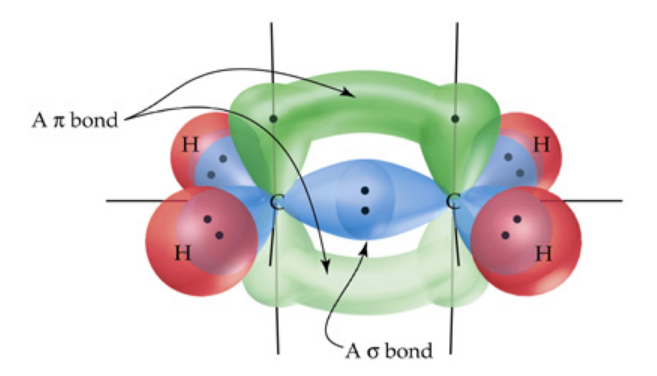

In [ ]:
Image(filename='pi.png', width=400, height=260)

Está descripción del doble enlace $C-C$ ha resultado ser muy útil para comprender el comportamiento de los electrones $\pi$. En sistemas más grandes, polienos conjugados y compuestos aromáticos, los electrones $\pi$ se pueden deslocalizar a los largo de los atomos de carbono que forman la molécula, es decir, se puede considerar que estos se distribuyen a los largo de toda la molécula y están bajo la influencia del potencial electrostático originado por los electrones que hacen parte de los enlaces $\sigma$. A está aproximación se le conoce como la $\textbf{aproximación del electrón}$ $\pi$. Las principales hipótesis del método de $Hückel$ en la formulación del determinante secular $det(H_{ij}-S_{ij}E)=0$, para el caso de hidrocarburos conjugados, son las siguientes:

1. Aproximación del electrón $\pi$.

Los electrones $\sigma$ se describen en términos de los órbitales híbridos localizados y los electrones $\pi$ se describen a través de funciones de onda moleculares que se extienden sobre cada uno de los atómos que aportan un electrón $\pi$ (los electrones $\pi$ están deslocalizados).

2. Las integrales de solapamiento son de la forma $S_{ij}=\delta_{ij}$. 

Partiendo de orbitales atómicos normalizados es claro que $S_{ii}=1$ y para orbitales $\phi_i$ y $\phi_j$ suficientemente separados es razonable asumir que $S_{ij}=0$. En general la integrales de solapamiento pueden alcanzar valores de hasta 0.25, lo cual dista considerablemente de cero. Sin embargo, al relajar está condición las energías se desplazan y sus ordenes relativos no se perturban de forma considerable, adicionalmente se simplifican los cálculos matemáticos.

3. Todas las integrales de Coulomb son iguales, es decir, $H_{ii}=\alpha$, donde $\alpha<0$.

Está aproximación es razonable para especies moleculares que no contienen heteroatomos. Parte de la justificación se tiene del $\textbf{teorema de Coulson-Rushbrooke}$, el cual establece que la densidad de carga en todos los átomos son iguales en hidrocarburos alternantes.

4. Las integrales de enlace $H_{ij}$ son iguales a cero, excepto para átomos adyacentes en los que $H_{ij}=\beta$, donde $\beta<0$.

Cuando dos átomos no comparten un enlace $\sigma$ la energía de interacción es muy pequeña, lo cual permite asumir que $H_{i,j}=0$. El parámetro $\beta$ es un parámetro característico de la teoría de Hückel que gobierna el espaciamiento relativo de los niveles de energía moleculares.

En la aproximación de Hückel, las integrales $\alpha$ y $\beta$ no se evalúan. A la cantidad $\beta$ se le asigna valores empíricos que permitan acercar tanto como sea posible la teoría con los valores experimentales. Usualmente a $\alpha$ se le asigna el valor de energía cero. 
 
De acuerdo con estas hipótesis para la molécula benceno  su determinante secular tiene la siguiente forma, si numeramos los átomos de la molécula de forma cíclica consecutiva.

$$
\left|
\begin{array}{cccccc}
\alpha-E   &   \beta     &     0      &    0    &   0   &   \beta  \\
\beta      &   \alpha-E  &  \beta     &  0   &    0  &  0 \\
0        &   \beta     &  \alpha-E  & \beta &  0  & 0 \\
0        &   0      &  \beta       & \alpha- E & \beta & 0    \\
0  &  0  &  0 & \beta  & \alpha-E  & \beta  \\
\beta      &   0   &  0     & 0 &  \beta  &   \alpha-E
\end{array}
\right|=0
$$

Note que el determinante anterior es cero si y sólo si el siguiente determinante vale cero, donde $x=\frac{\alpha-E}{\beta}$.

$$
\left|
\begin{array}{cccccc}
x   &   1     &     0      &    0    &   0   &   1  \\
1      &   x  &  1     &  0   &    0  &  0 \\
0        &   1     &  x  & 1 &  0  & 0 \\
0        &   0      &  1       & x & 1 & 0    \\
0  &  0  &  0 & 1  & x  & 1  \\
1     &   0   &  0     & 0 &  1  &   x
\end{array}
\right|=0
$$

La ecuación obtenida de este determinante es una ecuación polinomial de grado $6$, lo cual arroja  $6$ valores de energía para los $6$ orbitales moléculares, es decir, $E_i=\alpha-x_i\beta$ para $1\leq i \leq 6$, donde los $x_i$ son los ceros de la ecuación polinomial. Estos niveles de energía permitidos se comparan con respecto a $\alpha$; los orbitales moleculares $\psi$ para los cuales $E_{\psi}<\alpha$ se denominan $\textbf{orbitales moleculares enlazantes}$ y los orbitales moleculares $\psi$ para los cuales $E_{\psi} >\alpha$ se denominan $\textbf{orbitales moleculares antienlazantes}$. Los orbitales moleculares para los que $E=\alpha$, son $\textbf{orbitales de no enlace}$. 

## Etileno

Como hay dos átomos de carbono, las funciones de onda de los orbitales moleculares están dadas por: $\psi_i=c_{i1}\phi_1+c_{i2}\phi_2$, donde $1\leq i \leq 2$. Por lo tanto, el determinante secular es de tamaño 2x2 y la ecuación polinomial está dada por:

$$
\left|
\begin{array}{ccccc}
x   &  1    \\
1   &  x
\end{array}
\right|=0
$$

Para encontrar las soluciones de la ecuación secular se digita la matriz correspondiente $AE=Matrix([[x,1],[1,x]]) $ y se introduce en la función $Energía(AE)$. Esta función arroja los valores de energía, de mayor a menor, de los orbitales moleculares (estos valores se obtienen de la solución de la ecuación polinomial). Si se desea conocer la ecuación polinomial podemos emplear la función $Pol(AE)$.

In [ ]:
AE = Matrix([[x, 1], [1, x]]) 
AE 

⎡x  1⎤
⎢    ⎥
⎣1  x⎦

In [ ]:
Pol(AE)

In [ ]:
Energia(AE)

In [ ]:
AL= Matrix([[x, 1, 0], [1, x, 1], [0, 1, x]]) 

In [ ]:
AL

⎡x  1  0⎤
⎢       ⎥
⎢1  x  1⎥
⎢       ⎥
⎣0  1  x⎦

In [ ]:
Pol(AL)

In [ ]:
Energia(AL)

En el caso del etileno vemos que $E_{\psi_1}=\alpha+\beta$ y como tanto alpha como beta son negativos $\alpha+\beta<\alpha$, por lo tanto $\psi_1$ es enlazante, mientras que $\psi_2$ es antienlazante puesto que $E_{\psi_2}=\alpha-\beta>\alpha$. Siguiendo el $\textbf{principio de Aufbau}$ los dos electrones $\pi$ disponibles ocupan el orbital molecular $\psi_1$ con spines antiparalelos, por lo tanto la energía total de los electrones $\pi$ es $E_{\pi}=2(\alpha+\beta)$. Como la energía de un electrón en un orbital $p_z$ es $\alpha$, la energía del enlace $\pi$ es $2(\alpha+\beta)-2\alpha=2\beta$. Para calcular $E_{\pi}$ podemos utilizar la función $Epi(M,n)$, en donde $M$ es la matriz de coeficientes del determinante secular y $n$ es el número de electrones $\pi$. 

In [ ]:
Epi(AE,2)

In [ ]:
Epi(AL,4)

In [ ]:
Epi(AL,3)

In [ ]:
Epi(AL,4)

La función $Coef(M)$ arroja los coeficientes de los orbitales moleculares, en el caso del etileno hay dos orbitales de la forma $\psi_1=c_{11}\phi_1+c_{12}\phi_2$ y $\psi_2=c_{21}\phi_1+c_{22}\phi_2$. Estos valores aparecen para cada orbital molecular por filas y en orden descendente de energía (es decir, la primera fila corresponde a los coeficientes de $\psi_2$ y la siguiente a los de $\psi_1$). En la siguiente celda se ejecuta el programa para el etileno.

In [ ]:
Coef(AE)

⎡0.70711  -0.70711⎤
⎢                 ⎥
⎣0.70711  0.70711 ⎦

In [ ]:
Coef(AL)

⎡  0.5    -0.70711    0.5   ⎤
⎢                           ⎥
⎢0.70711    0.0     -0.70711⎥
⎢                           ⎥
⎣  0.5    0.70711     0.5   ⎦

La siguiente figura ubica el espaciamiento energético relativo de los orbitales moleculares para el etileno, de acuerdo con las energías predichas por el método de Hückel. Para esto empleamos la función $GrafE(A)$, la cual arroja los valores de energía de mayor a menor (la linea verde punteada simboliza el valor de referencia $\alpha$).

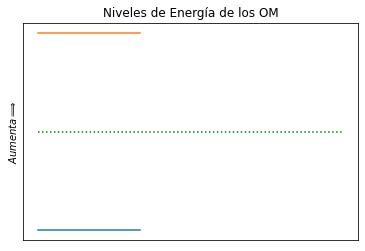

In [ ]:
GrafE(AE)

### Problema 1

Deduzca la forma del determinante secular para la siguientes especies químicas:

1. Butadieno
2. Ciclobutadieno
3. Trimetilenmetano
4. Radical alilo
5. Catión alilo
6. Anión alilo
7. Ciclopropenil
8. Pentadieno
9. Ciclopentadieno

En qué se diferencian y en que se asemejan 1,2 y 3. Haga la misma coparación para 4, 5, 6 y 7 (también para 8 y 9).

### Ejercicio 1

Para cada una de las especies anteriores calcule $Pol(A)$, $Energia(A)$, $Epi(A,n)$, $Coef(A,n)$ y $GrafE(A)$. Realice las comparaciones que se piden en los grupos del problema 1 y también entre grupos.

In [ ]:
AE = Matrix([[x, 1, 1], [1, x, 1], [1, 1, x]]) 

In [ ]:
AE

⎡x  1  1⎤
⎢       ⎥
⎢1  x  1⎥
⎢       ⎥
⎣1  1  x⎦

In [ ]:
Coef(AE)

⎡0.70711  -0.70711    0.0  ⎤
⎢                          ⎥
⎢0.40825  0.40825   -0.8165⎥
⎢                          ⎥
⎣0.57735  0.57735   0.57735⎦

In [ ]:
Energia(AE)

In [ ]:
Epi(AE,4)

## Molécula de butadieno

Aunque la molecula de butadieno tiene configuraciones $\textbf{cis}$ y $\textbf{trans}$, para el método de Hückel no habrá diferencias energéticas entre estas moleculas ya que las interacciones entre los átomos vecinos son despreciadas a menos que esten enlazados. Para los cálculos iniciales se considerará esta molecula de forma lineal. Los cuatro orbitales moleculares de esta molecula serán de la forma $\psi_i=c_{i1}\phi_1+c_{i2}\phi_2+c_{i3}\phi_3+c_{i4}\phi_4$, donde $1\leq i \leq 4$. A continuación se introduce la matriz correspondiente y se utiliza la función $Energia(M)$ para encontrar los valores de energía de los cuatro orbitales moleculartes.

In [ ]:
AB=Matrix([[x,1,0,0],[1,x,1,0],[0,1,x,1],[0,0,1,x]])
AB

⎡x  1  0  0⎤
⎢          ⎥
⎢1  x  1  0⎥
⎢          ⎥
⎢0  1  x  1⎥
⎢          ⎥
⎣0  0  1  x⎦

In [ ]:
Energia(AB)

Como vemos hay cuatro valores de energía para los orbitales moleculares, en su estado basal los 4 electrones $\pi$ del buatadieno ocupan los dos orbitales moleculares con menor energía (2 en cada orbital). La energía electrónica total debida a los electrones $\pi$ será $E_{\pi}=2(\alpha+1.6180\beta)+2(\alpha+0.6180\beta)=4\alpha+4.472\beta$, como se muestra a continuación.

In [ ]:
Epi(AB,4)

Es interesante comparar esta energía con la energía de la estructura localizada, es decir la molécula de butadieno en la que los dos dobles enlaces están entre los carbonos 1 y 2, y los carbonos 3 y 4. En la teoría de Hückel la estructura localizada es equivalente a dos moleculas de etileno independientes, como cada molécula de etileno tiene una energía $\pi$-electrónica de $2(\alpha+\beta)$, la $\textbf{energía de deslocalización}$ se define como $DE=E_{\pi}(butadieno)-E_{\pi}(etileno)=4\alpha+4.472\beta-2[2(\alpha+\beta)]=0.472\beta$. Está energía es una medida de la estabilización adicional que obtiene la molecula de butadieno si consideramos que los electrones se pueden mover en toda la molécula (es decir, los electrones están deslocalizados a lo largo de toda la estructura molecular). La función $DE(M,n)$, cuyos argumentos son la matrix asociada la determinante secular y el número de electrones $\pi$ permite calcular esta energía.

In [ ]:
DE(AB,4)

In [ ]:
DE(AL,4)

El butadieno tiene cuatro orbitales moleculares de la forma

$$\psi_4=c_{11}\phi_1+c_{12}\phi_2+c_{13}\phi_3+c_{14}\phi_4$$
$$\psi_3=c_{21}\phi_1+c_{22}\phi_2+c_{23}\phi_3+c_{24}\phi_4$$
$$\psi_2=c_{31}\phi_1+c_{32}\phi_2+c_{33}\phi_3+c_{34}\phi_4$$
$$\psi_1=c_{41}\phi_1+c_{42}\phi_2+c_{43}\phi_3+c_{44}\phi_4$$

Los valores de los coeficientes $c_{ij}$ se muestran a continuación.

In [ ]:
Coef(AB)

⎡0.37175  -0.6015    0.6015   -0.37175⎤
⎢                                     ⎥
⎢0.6015   -0.37175  -0.37175   0.6015 ⎥
⎢                                     ⎥
⎢0.6015   0.37175   -0.37175  -0.6015 ⎥
⎢                                     ⎥
⎣0.37175   0.6015    0.6015   0.37175 ⎦

La siguiente gráfica ubica los cuatro niveles de energía de los orbitales moleculares.

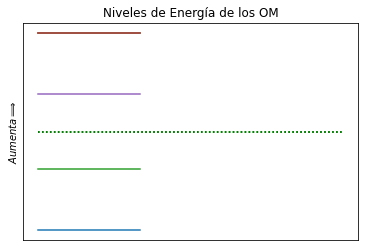

In [ ]:
GrafE(AB)

En algunos casos los coeficientes de los orbitales atómicos son más interesantes que las energías de los orbitales moleculares, ya que a partir de los coeficientes es posible definir catidades adicionales que se relacionan con la distribución de los electrones $\pi$ a los largo de la molécula. Como cada orbital molecular está normalizado, es decir $\sum_{i=1}^nc_{in}^2=1$, podemos interpretar $c_{in}^2$ como la fracción de carga (debida a los electrones $\pi$) sobre el $n$-ésimo átomo de carbono, como consecuencia debida a la presencia de un electrón en el i-ésimo orbital molecular. Así, la $\textbf{densidad electrónica total sobre el n-ésimo átomo de carbono}$, $q_n$, debida a los electrones $\pi$ es 

$$q_n=\sum_{i=1}^nn_ic_{in}^2$$

donde $n_i$ es el número de electrones en el $i$-ésimo orbital molecular. Esta densidad podemos calcularla con la función $ElecD(A,n)$, cuyos argumentos son la matriz de coeficientes $A$ y $n$ el número de electrones $\pi$. Esta función arroja un vector columna $[a_1,a_2,...,a_n]$ que muestra las densidad electrónica sobre el carbono $1,2,3,...,n$, respectivamente. 

In [ ]:
ElecD(AB,4)

⎡1.000000625⎤
⎢           ⎥
⎢1.000000625⎥
⎢           ⎥
⎢1.000000625⎥
⎢           ⎥
⎣1.000000625⎦

In [ ]:
ElecD(AE,4)

⎡1.3333452292⎤
⎢            ⎥
⎢1.3333452292⎥
⎢            ⎥
⎣ 1.3333445  ⎦

In [ ]:
ElecD(AL,3)

⎡1.0000045521⎤
⎢            ⎥
⎢1.0000091042⎥
⎢            ⎥
⎣1.0000045521⎦

In [ ]:
ElecD(AL,4)

⎡1.5000091042⎤
⎢            ⎥
⎢1.0000091042⎥
⎢            ⎥
⎣1.5000091042⎦

Como vemos la densidad electrónica es igual a $1$ para cada átomo de carbono, lo cual indica que los electrones $\pi$ en el butadieno están uniformemente distribuidos a lo largo de la molécula. Como es de esperarse la densidad electrónica para toda la molécula es 4.

Considere la molecula de etileno antes de la formación del enlace $\pi$, en esta situación cada átomo de carbono tiene asociado un electrón $\pi$ que esta disponible para la formación de un enlace. Por o tanto, un átomo de carbono neutro debe tener una densidad electrónica de $1$, de acuerdo con esto se define la $\textbf{densidad de carga q}$ en el $n$-ésimo átomo de carbono como $1$ menos la densidad de carga en este átomo, es decir $q_n=1-ElecD_n$. La función $Qn(A,n)$ que tiene como argumentos la matrix de coeficientes $A$ y el número de electrones $\pi$, arroja las densidades de carga para cada átomo de la molécula en cuestión.

In [ ]:
Qn(AB,4)


⎡0.0⎤
⎢   ⎥
⎢0.0⎥
⎢   ⎥
⎢0.0⎥
⎢   ⎥
⎣0.0⎦

In [ ]:
Qn(AL,3)

⎡        0.0         ⎤
⎢                    ⎥
⎢-1.00000000000655e-5⎥
⎢                    ⎥
⎣        0.0         ⎦

In [ ]:
Qn(AL,2)

⎡        0.5         ⎤
⎢                    ⎥
⎢-1.00000000000655e-5⎥
⎢                    ⎥
⎣        0.5         ⎦

In [ ]:
Qn(AL,4)

⎡      -0.50001      ⎤
⎢                    ⎥
⎢-1.00000000000655e-5⎥
⎢                    ⎥
⎣      -0.50001      ⎦

Como podemos observar la carga neta, debida a los electrones $\pi$, para cada átomo de carbono del butadieno es de cero.

### Ejercicio 2

Para las moléculas del problema $1$ encuentre las densidades electrónicas y las densidades de carga, compare los resultados por grupos, es decir, compare los resultados de las especies 1,2 y 3, los de las especies 4, 5, 6 y 7, y finalmente los de las especies 8 y 9.

Otra cantidad interesante que se puede definir en términos de los coeficientes de los orbitales moleculares es el $\textbf{orden de enlace}$ $\pi$. El producto $c_{ir}c_{is}$ se puede interpretar como la carga electrónica (a causa por los electrones $\pi$), en el $i$-ésimo orbital molecular entre dos átomos de carbono adyacentes $r$ y $s$. Si $n_i$ es el número de electrones $\pi$ en el $i$-ésimo orbital molecular, se define el orden de enlace entre dos átomos adyacentes $r$ y $s$ por

$$P^{\pi}_{rs}=\sum_{i=1}^n n_ic_{ir}c_{is}$$

Esta cantidad es una medida del carácter multiple de un enlace (se ha correlacionado con las longitudes de enlace y las constantes de fuerza vibracionales). Estos valores se calculan para las molécula de etileno y butadieno a través de la función $Oen(A,n)$ (programada para moleculas lineales o cíclicas), como sigue:

In [ ]:
Oen(AE,2)

⎡0.666666045⎤
⎢           ⎥
⎣0.666666045⎦

Para el etileno el orden de enlace entre los carbonos 1 y 2 es de $1.0$, lo que indica que los enlaces entre los átomos de carbono 1-2 y 3-4 del butadieno, no son del todo dobles enlaces. Finalmente calculamos el HOMO-LUMO gap para el etileno y el butadieno , a través de la función $Bgap(A,n)$.

In [ ]:
Oen(AL,2)

⎡0.70711⎤
⎢       ⎥
⎣0.70711⎦

In [ ]:
Oen(AL,3)

⎡0.70711⎤
⎢       ⎥
⎣0.70711⎦

### Ejercicio 3

1. Para el ciclobutadieno calcule $Energia(A)$. ¿Qué dice la regla de Hund sobre el estado basal de ciclobutadieno?. Compare la estabilidad del ciclobutadieno con respecto a dos moleculas de etileno aisladas.
2. Haga el análisis anterior para el trimetilenmetano.
3. Calcule las energías de los orbitales moleculares del biciclobutadieno y calcule también $E_{\pi}$. ¿Qué puede concluir al respecto?
4. Calcule la densidad electrónica en el catión butadieno $C_4H_6^{+}$ y el anión butadieno  $C_4H_6^{-}$. 

## Bibliografía

Atkins, P. Physical Chemistry, Ed 8, WH Freeman, 2006.

Hanna, M. Quantum Mechanics in Chemistry,BENJAMIN INC, 1969.

Levine, I., Quantum Chemistry, Ed 2, Allyn and Bacon, 1974.

Liberles, A. Molecular Orbital Theory, HRW, 1966.

McQuarrie D., Quantum Chemistry, Viva Books, 2016.


In [ ]:
K= Matrix([[x,1,0,0,0,1], [1,x,1,0,0,0],[0,1,x,1,0,0],[0,0,1,x,1,0],[0,0,0,1,x,1],[1,0,0,0,1,x]]) 
K 

⎡x  1  0  0  0  1⎤
⎢                ⎥
⎢1  x  1  0  0  0⎥
⎢                ⎥
⎢0  1  x  1  0  0⎥
⎢                ⎥
⎢0  0  1  x  1  0⎥
⎢                ⎥
⎢0  0  0  1  x  1⎥
⎢                ⎥
⎣1  0  0  0  1  x⎦

In [ ]:
Pol(K)

In [ ]:
Energia(K)

In [ ]:
Epi(K,6)

In [ ]:
Coef(K)

⎡0.40825  -0.40825  0.40825   -0.40825  0.40825  -0.40825⎤
⎢                                                        ⎥
⎢  0.5      -0.5      0.0       0.5      -0.5      0.0   ⎥
⎢                                                        ⎥
⎢0.28868  0.28868   -0.57735  0.28868   0.28868  -0.57735⎥
⎢                                                        ⎥
⎢  0.5      0.5       0.0       -0.5     -0.5      0.0   ⎥
⎢                                                        ⎥
⎢0.28868  -0.28868  -0.57735  -0.28868  0.28868  0.57735 ⎥
⎢                                                        ⎥
⎣0.40825  0.40825   0.40825   0.40825   0.40825  0.40825 ⎦

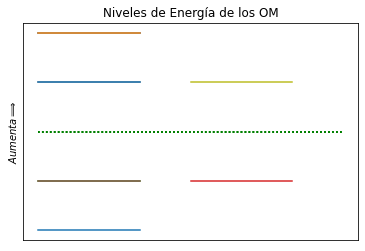

In [ ]:
GrafE(K)